In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# spare_part_purchase.csv

In [2]:
# read data & rename cols
df_price = pd.read_csv('price_overview.csv', sep=';')
df_part = pd.read_csv('spare_part_purchase.csv', parse_dates=['Date of purchase', 'Date of delivery'])
df_part = df_part.rename(columns={'Date of purchase': 'Date_purchase', 'Date of delivery': 'Date_delivery', 'Part id':'Part_id'})

***Explore Dataset***

In [3]:
print("SHAPE:", "\n", df_part.shape, "\n", "\n",
     "INDEX (row names):", "\n", df_part.index, "\n", "\n",
     "DTYPES (datatypes of col):", "\n", df_part.dtypes, "\n", "\n",
     "DESCRIBE (numeric cols):", "\n", df_part.describe(), "\n", "\n",
     "IS-NA (Sum of NaN per col):", "\n", df_part.isna().sum(), "\n", "\n",
     "HEAD:", "\n", df_part.head(), "\n", "\n",
     "TAIL:", "\n", df_part.tail(), "\n"    )
print("Categories:", "\n")
cols_cat = ["Part_id","Part", "Machine"] 
for cat in cols_cat:
    display(df_part.loc[:, cat].value_counts(dropna=False).to_frame())
    print("---------------------------")

SHAPE: 
 (12300, 5) 
 
 INDEX (row names): 
 RangeIndex(start=0, stop=12300, step=1) 
 
 DTYPES (datatypes of col): 
 Machine                  object
Date_purchase    datetime64[ns]
Date_delivery    datetime64[ns]
Part                     object
Part_id                   int64
dtype: object 
 
 DESCRIBE (numeric cols): 
                        Date_purchase                  Date_delivery  \
count                          12300                          12300   
mean   2024-03-02 11:43:50.634146560  2026-09-10 14:35:35.414634240   
min              1900-01-01 00:00:00            2025-09-13 00:00:00   
25%              2026-03-26 00:00:00            2026-04-06 00:00:00   
50%              2026-07-03 12:00:00            2026-07-13 00:00:00   
75%              2026-10-10 00:00:00            2026-10-16 06:00:00   
max              2036-01-01 00:00:00            2036-01-08 00:00:00   
std                              NaN                            NaN   

            Part_id  
count  1.230000

,count
Part_id,
10234567,2010
20345672,1756
10234568,1753
20345671,1631
50678905,1272
50678904,1238
30456789,1065
40567890,837
50678902,329


---------------------------


,count
Part,
knife_1,1961
vacuum_valve_2,1719
knife_2,1709
vacuum_valve_1,1582
lower_web_film,1248
upper_web_film,1224
heater,1037
battery,828
lifting_unit,168


---------------------------


,count
Machine,
RX40_222222,4142
R535_333333,4124
RX40_111111,4034


---------------------------


***Cleaning / Plausibility-Checks***

***Part_id vs. Part***

In [4]:
df_part.groupby('Part_id')['Part'].unique()

Part_id
10234567                                   [knife_1, knfie_1]
10234568                                   [knife_2, knife 2]
20345671                      [vacuum_valve_1, vacum_valve_1]
20345672                      [vacuum_valve_2, vacuum_valv_2]
30456789                                      [heater, heatr]
40567890                                 [battery, battery_x]
50678901    [heater, knife_2, knife_1, vacum_valve_1, vacu...
50678902    [vacuum_valve_2, knife_1, vacuum_valve_1, knif...
50678903                          [lifting_unit, lfting_unit]
50678904                     [upper_web_film, upper web film]
50678905                       [lower_web_film, lowerwebfilm]
Name: Part, dtype: object

--> most IDs with more than one part are resulting from spelling errors. However, IDs 50678901 and 50678902 need further analysis

In [5]:
# IDs 50678901 and 50678902
mask_id = df_part['Part_id'].isin([50678901, 50678902])
display(
    pd.crosstab(
        df_part.loc[mask_id, 'Part'],
        df_part.loc[mask_id, 'Part_id']
        )
)
print('File price_overview.csv:\n')
df_price.groupby('Part id ')['Part'].unique()

Part_id,50678901,50678902
Part,,
battery,6,18
die-set,0,1
die_set,0,78
heater,14,16
heatr,1,1
knfie_1,0,2
knife 2,0,1
knife_1,13,47
knife_2,17,37


File price_overview.csv:



Part id 
10234567.0                  [knife_1, knife_1_variant]
10234568.0                  [knife_2, knife_2_variant]
20345671.0    [vacuum_valve_1, vacuum_valve_1_variant]
20345672.0    [vacuum_valve_2, vacuum_valve_2_variant]
30456789.0                    [heater, heater_variant]
40567890.0                                   [battery]
50678901.0                             [machine_frame]
50678902.0                                   [die_set]
50678903.0                              [lifting_unit]
50678904.0                            [upper_web_film]
50678905.0                            [lower_web_film]
Name: Part, dtype: object

--> In price_overview.csv, IDs 50678901/2 are assignet to the part names 'machine_frame' and 'die_set', respectively. 

In spare_part_purchase.csv, the same names are the highest counting names within the corresponding ID.

Consequently, it is resonable to assign 50678901 to 'machine_frame' and 50678902 to 'die_set', though a further clarification with the department would be necessary.

In [6]:
# Assign part to part_id
df_part.loc[ df_part['Part_id'].isin([50678901]), 'Part' ] = 'machine_frame'
df_part.loc[ df_part['Part_id'].isin([50678902]), 'Part' ] = 'die_set'

***Plot weekly timeseries and filter to plausible dates***

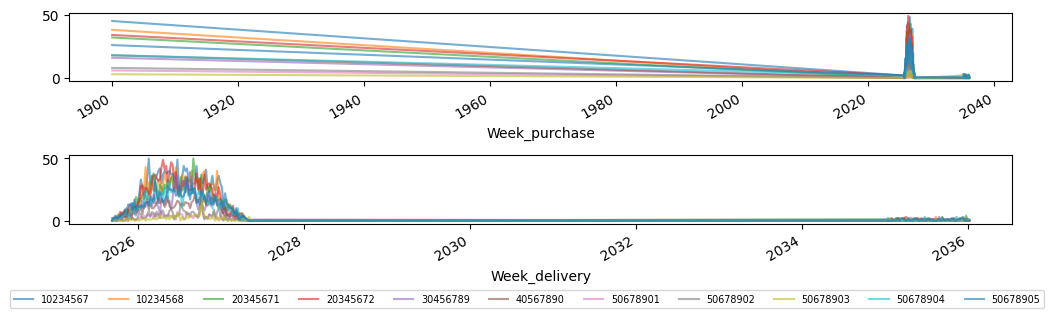

In [7]:
# weekly timeframe
df_part['Week_purchase'] = (
    df_part['Date_purchase']
    .dt.to_period('W-SUN')
    .dt.start_time
)
df_part['Week_delivery'] = (
    df_part['Date_delivery']
    .dt.to_period('W-SUN')
    .dt.start_time
)
# plot all Parts
fig, ax = plt.subplots(nrows=2, ncols=1, figsize=(10, 3))
pd.crosstab(df_part['Week_purchase'], df_part['Part_id']).plot(
    alpha=.6, ax=ax[0], legend=False
)
pd.crosstab(df_part['Week_delivery'], df_part['Part_id']).plot(
    alpha=.6, ax=ax[1], legend=False
)
handles, labels = ax[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.05),
    ncol=11,
    fontsize='x-small'
)
plt.tight_layout()

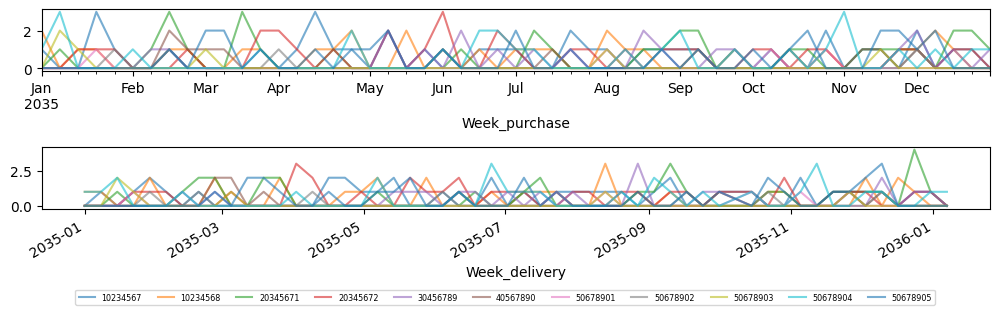

In [8]:
# plot dates after year 2030
mask = (
    df_part['Date_purchase'].between('2030-01-01', '2038-01-01')
    & df_part['Date_delivery'].between('2030-01-01', '2038-01-01')
)

# plot
fig, ax = plt.subplots(nrows=2, ncols=1, figsize=(10, 3))

pd.crosstab(index=df_part.loc[mask, 'Week_purchase'],
            columns=df_part.loc[mask, 'Part_id']
           ).plot(alpha=.6, legend=False, ax=ax[0])
pd.crosstab(index=df_part.loc[mask, 'Week_delivery'],
            columns=df_part.loc[mask, 'Part_id']
           ).plot(alpha=.6, legend=False, ax=ax[1])

handles, labels = ax[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.05),
    ncol=11,
    fontsize='xx-small'
)
plt.tight_layout()

--> low counts and 10 years without any purchases in between --> errors, probably typos (2035 instead of 2025) --> further analysis without 2030s

(11818, 7)


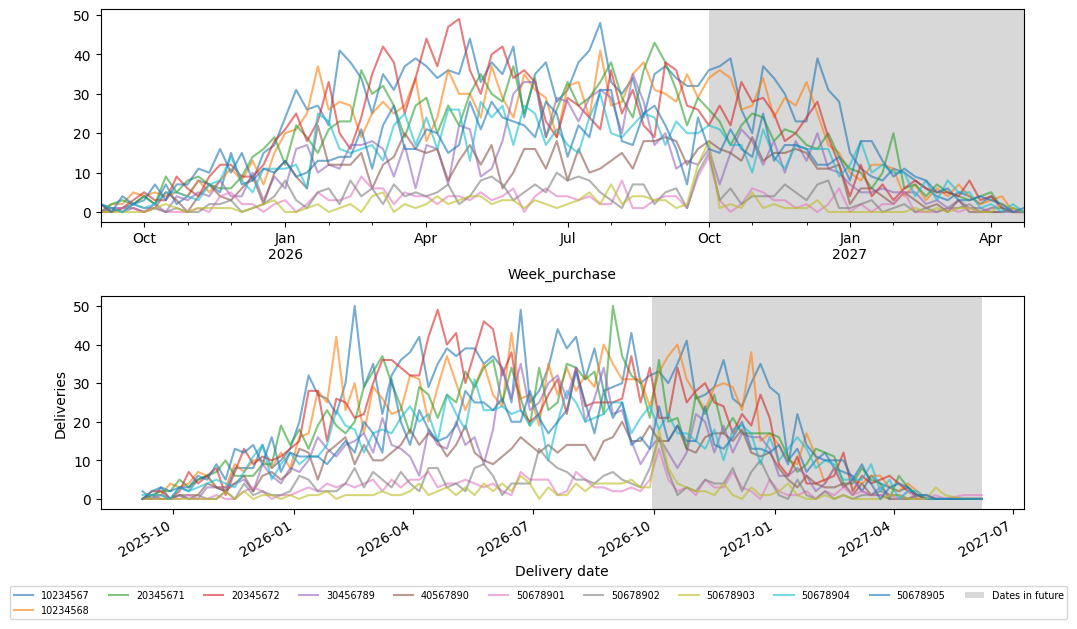

In [9]:
# plot weekly data without unplausible dates
mask = (
    df_part['Date_purchase'].between('2020-01-01', '2030-01-01')
    & df_part['Date_delivery'].between('2020-01-01', '2030-01-01')
)
df_part = df_part.loc[mask, :] # delete unplausible dates from dataframe
print(df_part.shape)

# plot
fig, ax = plt.subplots(nrows=2, ncols=1, figsize=(10, 6))

pd.crosstab(index=df_part.loc[:, 'Week_purchase'],
            columns=df_part.loc[:, 'Part_id']
           ).plot(alpha=.6, legend=False, ax=ax[0])
pd.crosstab(index=df_part.loc[:, 'Week_delivery'],
            columns=df_part.loc[:, 'Part_id']
           ).plot(alpha=.6, legend=False, ax=ax[1], ylabel='Deliveries', xlabel='Delivery date')

for a in ax:
    a.axvspan(
        '2026-09-30', df_part.loc[mask, 'Week_delivery'].max(),
        facecolor='grey', alpha=0.3, label='Dates in future'
    )

handles, labels = ax[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.05),
    ncol=11,
    fontsize='x-small')

plt.tight_layout()

--> Orders lying in the future (grey) are also included in the dataset. Their origin is unclear (forecasts? planned? etc.). 
In the following analysis they will be considered as planned orders. Therefore, they are treated differently than past orders. Rows are marked accoringly by introducing column "Future".

In [10]:
# add column to indicate future dates 
df_part.loc[:, 'Future'] = 0
df_part.loc[ df_part.loc[:, 'Date_delivery'] >= '2026-10-01' , 'Future'] = 1

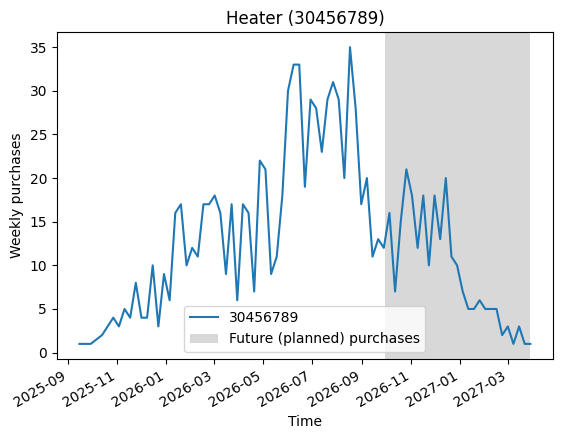

In [11]:
# Plot Heater
mask_part_id = df_part['Part_id'] == 30456789

ax = pd.crosstab(
    index=df_part.loc[mask_part_id, 'Week_purchase'],
    columns=df_part.loc[mask_part_id, 'Part_id']
).plot(title='Heater (30456789)', ylabel='Weekly purchases', xlabel='Time')

ax.axvspan(
    '2026-09-30', df_part.loc[mask_part_id, 'Week_purchase'].max(),
    facecolor='grey', alpha=0.3, label='Future (planned) purchases'
)
ax.legend()

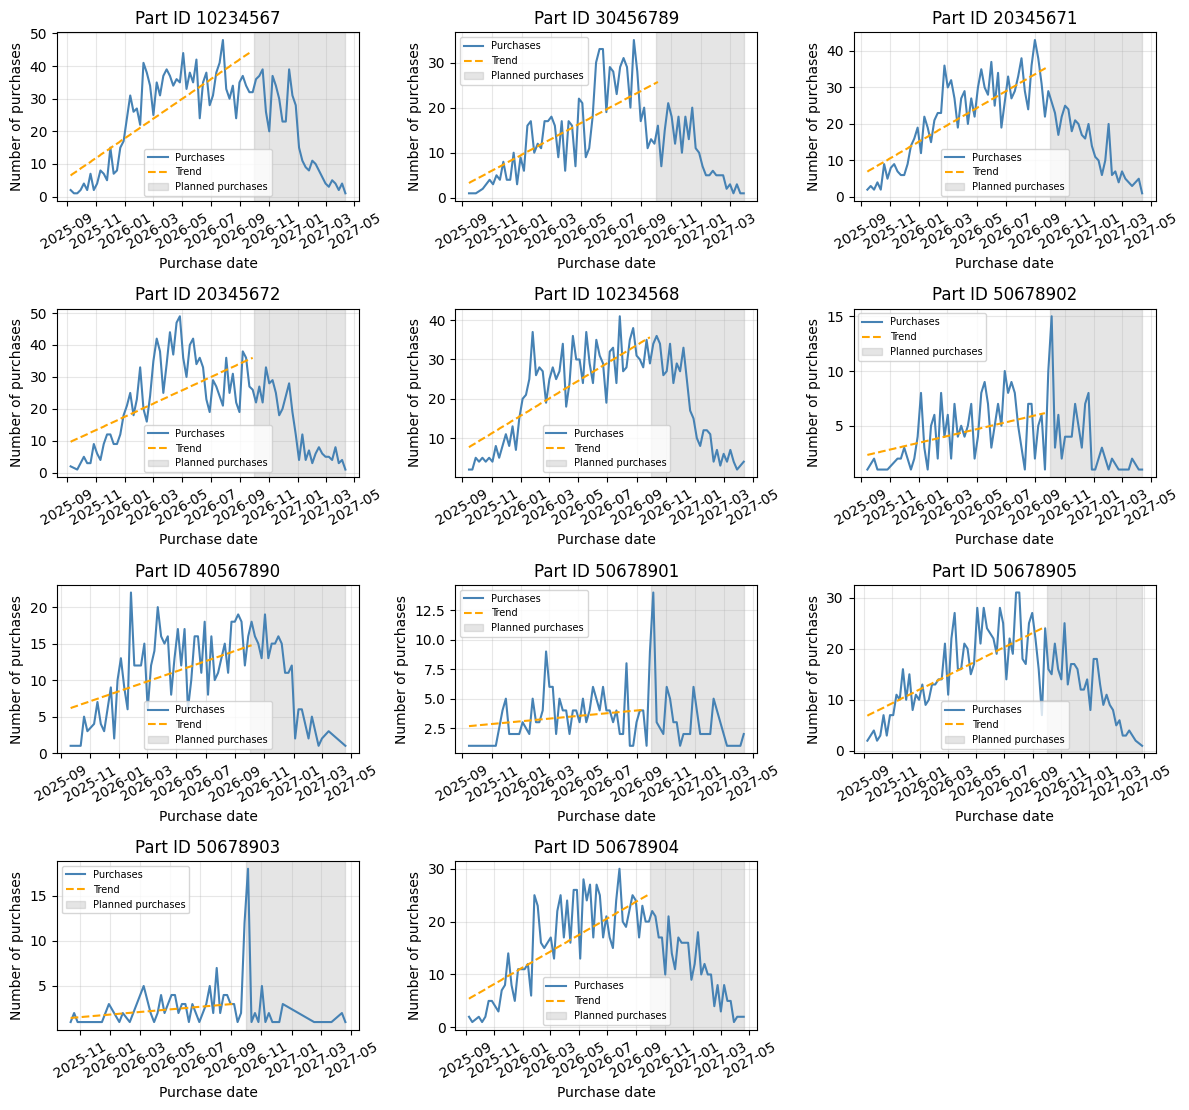

In [12]:
# Plot purchases over time per Product ID with a trend based only on completed orders

part_ids = df_part['Part_id'].unique()

ncols = 3
nrows = 4

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(12, 2.8 * nrows),
    squeeze=False
)

cutoff_date = pd.Timestamp('2026-10-01')

for i, part_id in enumerate(part_ids):
    ax = axes.flat[i]
    df_id = df_part.loc[df_part['Part_id'] == part_id].copy()
    df_id['Week_purchase'] = pd.to_datetime(df_id['Week_purchase'])

    # Plot all purchases
    purchases = df_id.groupby('Week_purchase').size().sort_index()
    ax.plot(
        purchases.index,
        purchases.values,
        label='Purchases',
        color='steelblue'
    )

    # Calculate trend using only completed orders
    df_completed = df_id.loc[df_id['Future'] == 0]
    trend = df_completed.groupby('Week_purchase').size().sort_index()
    x = trend.index.map(pd.Timestamp.toordinal).to_numpy(dtype=float)
    y = trend.values
    slope, intercept = np.polyfit(x, y, 1)

    x_line = np.linspace(x.min(), x.max(), 100)
    y_line = slope * x_line + intercept
    dates_line = pd.to_datetime([
        pd.Timestamp.fromordinal(int(day))
        for day in x_line
    ])

    ax.plot(
        dates_line,
        y_line,
        color='orange',
        linestyle='--',
        label='Trend'
    )

    ax.axvspan(
        cutoff_date,
        max(purchases.index.max(), cutoff_date + pd.Timedelta(days=1)),
        color='grey',
        alpha=0.2,
        label='Planned purchases'
    )

    ax.set_title(f'Part ID {part_id}')
    ax.set_xlabel('Purchase date')
    ax.set_ylabel('Number of purchases')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
    ax.tick_params(axis='x', labelrotation=30)

# Remove unused subplots
for j in range(len(part_ids), nrows * ncols):
    fig.delaxes(axes.flat[j])

fig.tight_layout()
plt.show()

***Shipping times***

Cleaning: negative shipping times

In [13]:
# calculate shipping time in days

df_part['Shipping_days'] = (
    df_part['Date_delivery'] - df_part['Date_purchase']
).dt.days.astype(int)

# negative shipping times

print('Number of negative shipping times:', (df_part['Shipping_days'] < 0).sum())
print('\nNumber of negative shipping times per Part, Machine, and future orders:')
mask_negative = (df_part['Shipping_days'] < 0)
for cat in ["Part_id", "Machine", "Future"] :
    print('\n', df_part.loc[mask_negative, cat].value_counts(dropna=False))

Number of negative shipping times: 351

Number of negative shipping times per Part, Machine, and future orders:

 Part_id
20345671    50
10234568    49
10234567    48
50678904    47
20345672    46
50678905    32
30456789    30
40567890    29
50678902     8
50678901     7
50678903     5
Name: count, dtype: int64

 Machine
R535_333333    134
RX40_222222    113
RX40_111111    104
Name: count, dtype: int64

 Future
0    278
1     73
Name: count, dtype: int64


--> entries with negative shipping time show no noticable distribution across Part_id or Machine and exist also in future orders. The cause of negative values cannot be determined and only 351/11818 entries are affected. Therefore, entries with negative values will be deleted.

In [14]:
# delete rows with negative shipping times
df_part = df_part.loc[df_part['Shipping_days'] >= 0].copy()
df_part.shape

(11467, 9)

Distributions of shipping time, incl. per Product, Machine:

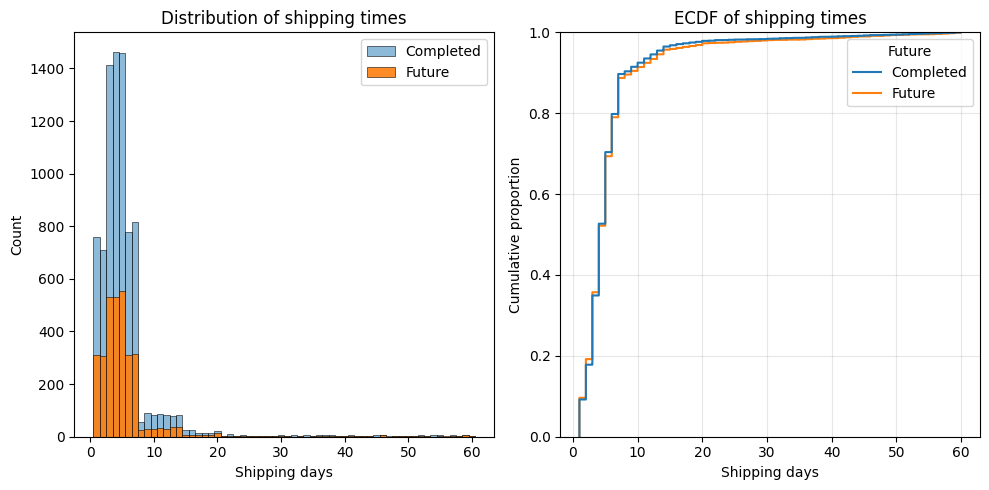

In [15]:
# Plot distribution of shipping time (all parts, machines)

df_plot = df_part.dropna(subset=['Shipping_days', 'Future']).copy()
df_plot['Future'] = df_plot['Future'].map({0: 'Completed', 1: 'Future'})

fig, ax = plt.subplots(1, 2, figsize=(10, 5))

# Histogram: plot Completed first, then Future on top
sns.histplot(
    data=df_plot[df_plot['Future'] == 'Completed'],
    x='Shipping_days',
    discrete=True,
    color='C0',
    alpha=0.5,
    element='bars',
    ax=ax[0],
    label='Completed'
)

sns.histplot(
    data=df_plot[df_plot['Future'] == 'Future'],
    x='Shipping_days',
    discrete=True,
    color='C1',
    alpha=0.9,
    element='bars',
    ax=ax[0],
    label='Future'
)

ax[0].set(title='Distribution of shipping times',
          xlabel='Shipping days', ylabel='Count')
ax[0].legend()

# ECDF
sns.ecdfplot(
    data=df_plot, x='Shipping_days', hue='Future',
    hue_order=['Completed', 'Future'], ax=ax[1]
)

ax[1].set(title='ECDF of shipping times',
          xlabel='Shipping days', ylabel='Cumulative proportion')
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

--> Future (planned) shipping times can also be very long. Therefore, long shipping times (>= 7 days) observed in the past are not necesarily abnormal/critical.

C:\Users\mariu\PycharmProjects\pythonProject\venv\Lib\site-packages\seaborn\axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


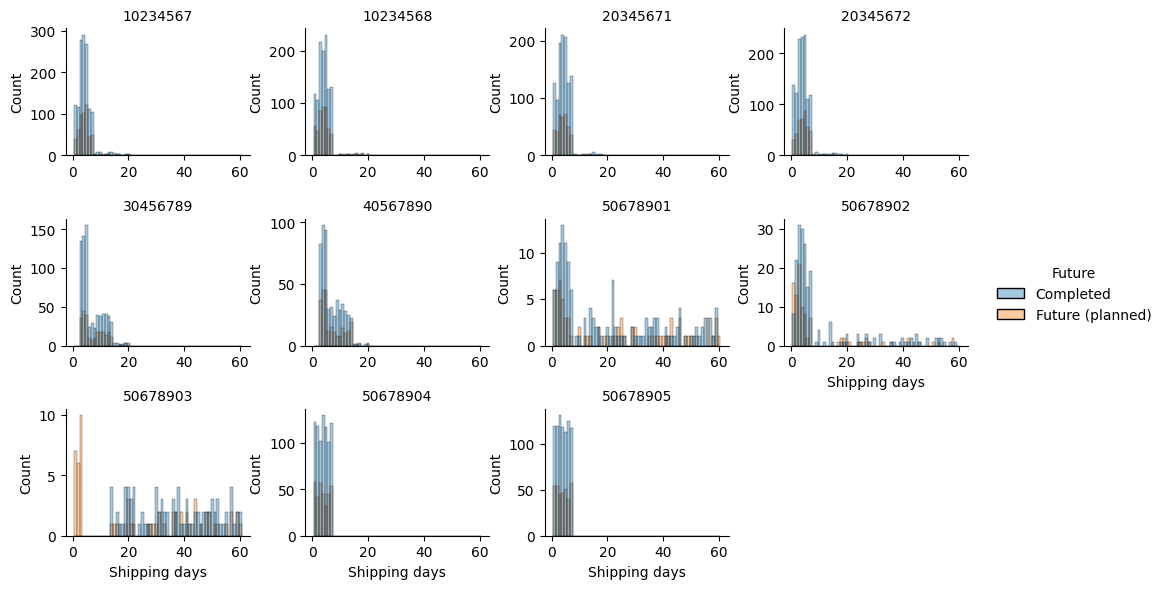

In [16]:
# Distribution of shipping times by Part ID and Future status

df_plot = df_part.dropna(subset=['Shipping_days', 'Part_id', 'Future']).copy()
df_plot['Future'] = df_plot['Future'].map({0: 'Completed', 1: 'Future (planned)'})

g = sns.displot(
    data=df_plot,
    x='Shipping_days',
    hue='Future',
    col='Part_id',
    col_wrap=4,
    kind='hist',
    discrete=True,
    alpha=0.4,
    height=2,
    aspect=1.25,
    facet_kws={'sharey': False}
)

g.set_titles('{col_name}')

for ax in g.axes.flat:
    ax.set_xlabel('Shipping days')
    ax.set_ylabel('Count')

    # Show tick marks and tick labels on every subplot
    ax.tick_params(axis='x', labelbottom=True)
    ax.tick_params(axis='y', labelleft=True)

g.figure.subplots_adjust(hspace=0.5, wspace=0.3)
plt.show()

--> Several planned orders of part 50678903 have very low shipping time. These will be deleted for further analysis.

In [17]:
# delete unplausible planned shipping times for Part 50678903
df_part = df_part[~((df_part['Part_id'] == 50678903) & (df_part['Shipping_days'] < 10))]

C:\Users\mariu\PycharmProjects\pythonProject\venv\Lib\site-packages\seaborn\axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


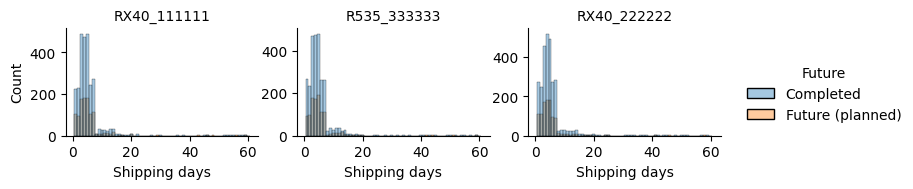

In [18]:
# Distribution of shipping times by Machine and Future status

df_plot = df_part.dropna(subset=['Shipping_days', 'Part_id', 'Future']).copy()
df_plot['Future'] = df_plot['Future'].map({0: 'Completed', 1: 'Future (planned)'})

g = sns.displot(
    data=df_plot,
    x='Shipping_days',
    hue='Future',
    col='Machine',
    col_wrap=3,
    kind='hist',
    discrete=True,
    alpha=0.4,
    height=2,
    aspect=1.25,
    facet_kws={'sharey': False}
)

g.set_axis_labels('Shipping days', 'Count')
g.set_titles('{col_name}')
g.figure.subplots_adjust(hspace=0.3, wspace=0.2)
plt.show()

In [19]:
# Statistics
    # Shipping time by part ID and Future status

part_stats = (
    df_part.groupby(['Part_id', 'Future'])['Shipping_days']
    .agg(count='count', median='median', mean='mean', SD='std')
    .unstack('Future')
)

part_stats = part_stats.swaplevel(axis=1).sort_index(axis=1, level=0)
part_stats = part_stats.sort_values((0, 'mean'), ascending=False)

display(part_stats)

    # Shipping time by machine and Future status

machine_stats = (
    df_part.groupby(['Machine', 'Future'])['Shipping_days']
    .agg(count='count', median='median', mean='mean', SD='std')
    .unstack('Future')
)

machine_stats = machine_stats.swaplevel(axis=1).sort_index(axis=1, level=0)
machine_stats = machine_stats.sort_values((0, 'mean'), ascending=False)

display(machine_stats)

Future            0                                  1                        
                 SD count       mean median         SD count       mean median
Part_id                                                                       
50678903  13.821535    90  36.433333   36.5  13.559579    41  37.707317   39.0
50678901  18.846059   146  20.671233   14.0  19.991292    77  22.649351   19.0
50678902  14.795622   207  11.642512    5.0  13.785866    99   9.636364    3.0
40567890   3.621438   541   7.000000    5.0   3.829705   239   7.037657    5.0
30456789   3.815264   751   6.854860    5.0   3.992778   248   7.467742    6.0
10234568   2.477050  1155   4.349784    4.0   2.763911   479   4.327766    4.0
10234567   2.546327  1350   4.339259    4.0   2.515472   531   4.384181    4.0
20345671   2.317078  1128   4.295213    4.0   2.502677   389   4.267352    4.0
20345672   2.531680  1229   4.257120    4.0   2.324466   414   4.497585    4.0
50678905   1.994848   840   3.982143    4.0   2.063895   346   3.965318    4.0
50678904   2.012738   811   3.972873    4.0   2.084159   333   3.906907    4.0

Future              0                                1                       
                   SD count      mean median        SD count      mean median
Machine                                                                      
RX40_111111  6.226498  2691  5.535489    4.0  6.988050  1071  5.809524    4.0
R535_333333  6.087831  2740  5.449270    4.0  6.568790  1080  5.775926    5.0
RX40_222222  6.047398  2817  5.445864    4.0  7.038531  1045  5.659330    4.0

--> Especially the three part IDs 50678901/2/3 show increased average shipping times and high standard deviations. Therefore, a defect in these parts may potentially result in a critically long downtime.

--> Using orders that lie in the future (planned orders) as a reference, long shipping times appear not abnormal. However, for 50678902, past shipping times exceeded planned shipping times: median 5 vs. 3. However, some planned shipping times appear to be too short (similarily to 50678903, see above) and may bias this comparison.

***Spare parts per Machine-Type***

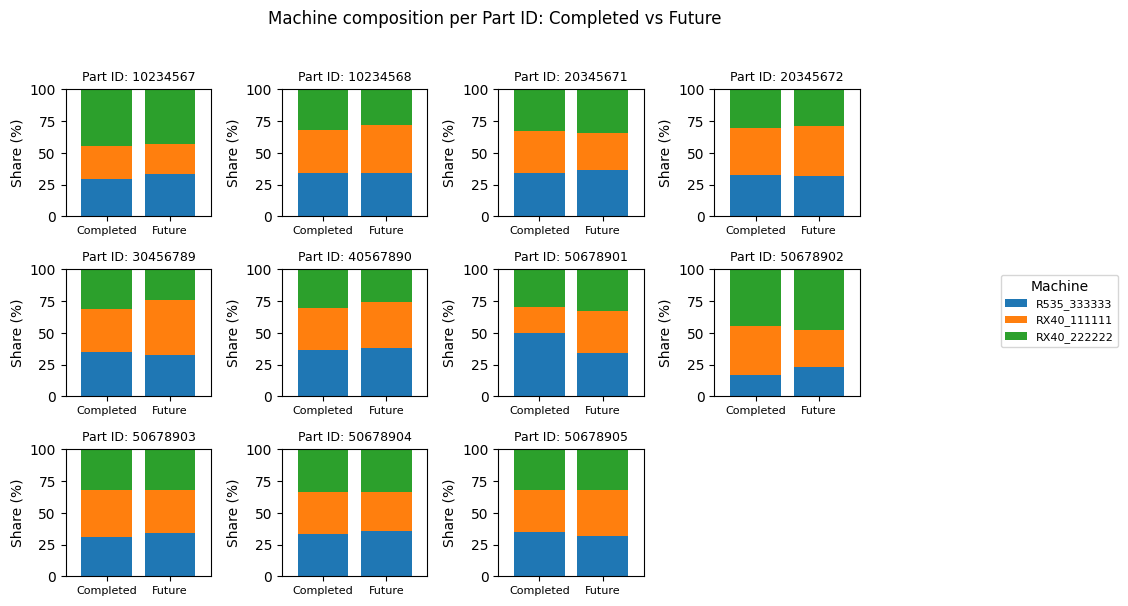

In [20]:
# 100% stacked bars: machine distribution per part ID and delivery status

part_ids = sorted(df_part['Part_id'].dropna().unique())
ncols = 4
nrows = (len(part_ids) + ncols - 1) // ncols

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(10, 2 * nrows),
    squeeze=False
)
axes = axes.flatten()

for i, part_id in enumerate(part_ids):
    data = df_part[df_part['Part_id'] == part_id]

    ct = pd.crosstab(data['Future'], data['Machine'], normalize='index') * 100
    ct = ct.reindex(index=[0, 1], fill_value=0)

    ct.index = ['Completed', 'Future']
    ct.plot(
        kind='bar',
        stacked=True,
        ax=axes[i],
        width=0.8,
        legend=False
    )

    axes[i].set_title(f'Part ID: {part_id}', fontsize=9)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Share (%)')
    axes[i].set_ylim(0, 100)
    axes[i].tick_params(axis='x', rotation=0, labelsize=8)

for ax in axes[len(part_ids):]:
    ax.set_visible(False)

# Shared legend for all subplots
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    title='Machine',
    loc='center left',
    bbox_to_anchor=(1.0, 0.5),
    fontsize=8
)

fig.suptitle(
    'Machine composition per Part ID: Completed vs Future',
    y=1.002
)
plt.tight_layout(rect=[0, 0, 0.88, 0.98])
plt.show()

--> For most parts, orders are distributed equally over machine types with only small differences between completed and future orders. Especially parts 50678901/2 show a different pattern.

***Additional Plots (optional)***

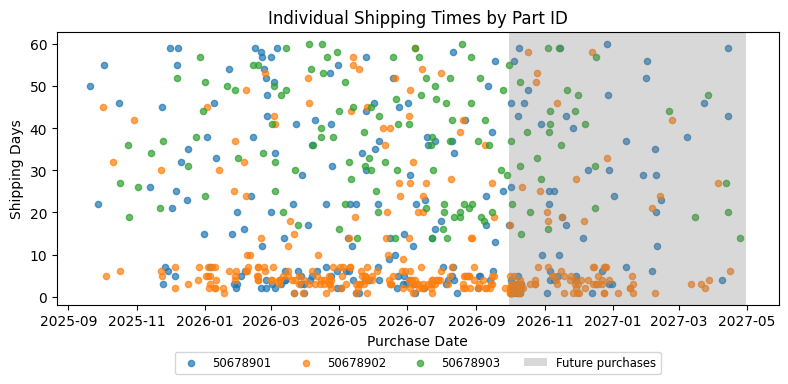

In [21]:
# Individual shipping times over time
mask_part_id = df_part['Part_id'].isin([50678901, 50678902, 50678903])

fig, ax = plt.subplots(figsize=(8, 4))

for part_id, group in df_part[mask_part_id].groupby('Part_id'):
    ax.scatter(
        group['Date_purchase'],
        group['Shipping_days'],
        label=part_id,
        alpha=0.7,
        s=20
    )

ax.set_xlabel('Purchase Date')
ax.set_ylabel('Shipping Days')
ax.set_title('Individual Shipping Times by Part ID')

ax.axvspan(
    '2026-09-30', df_part['Date_purchase'].max(),
    facecolor='grey', alpha=0.3, label='Future purchases'
)

ax.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, -0.15),
    ncol=11,
    fontsize='small'
)

plt.tight_layout()
plt.show()

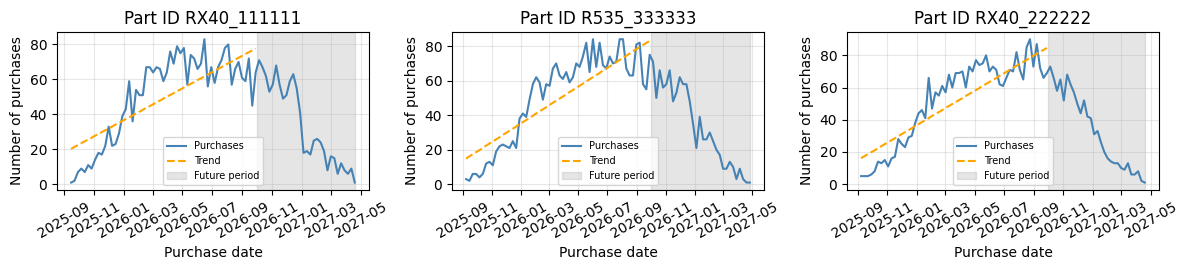

In [22]:
# Plot purchases over time by Machine with a trend based only on completed orders

part_ids = df_part['Machine'].dropna().unique()

ncols = 3
nrows = 1

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(12, 2.8 * nrows),
    squeeze=False
)
cutoff_date = pd.Timestamp('2026-10-01')

for i, part_id in enumerate(part_ids):
    ax = axes.flat[i]

    df_id = df_part.loc[df_part['Machine'] == part_id].copy()
    df_id['Week_purchase'] = pd.to_datetime(df_id['Week_purchase'])

    purchases = df_id.groupby('Week_purchase').size().sort_index()
    ax.plot(
        purchases.index,
        purchases.values,
        label='Purchases',
        color='steelblue'
    )
    # Calculate trend using only completed orders
    df_completed = df_id.loc[df_id['Future'] == 0]
    trend = df_completed.groupby('Week_purchase').size().sort_index()
    x = trend.index.map(pd.Timestamp.toordinal).to_numpy(dtype=float)
    y = trend.values
    slope, intercept = np.polyfit(x, y, 1)

    x_line = np.linspace(x.min(), x.max(), 100)
    y_line = slope * x_line + intercept
    dates_line = pd.to_datetime([
        pd.Timestamp.fromordinal(int(day))
        for day in x_line
    ])
    ax.plot(
        dates_line,
        y_line,
        color='orange',
        linestyle='--',
        label='Trend'
    )
    ax.axvspan(
        cutoff_date,
        max(purchases.index.max(), cutoff_date + pd.Timedelta(days=1)),
        color='grey',
        alpha=0.2,
        label='Future period'
    )

    ax.set_title(f'Part ID {part_id}')
    ax.set_xlabel('Purchase date')
    ax.set_ylabel('Number of purchases')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
    ax.tick_params(axis='x', labelrotation=30)

# Remove unused subplots
for j in range(len(part_ids), nrows * ncols):
    fig.delaxes(axes.flat[j])

fig.tight_layout()
plt.show()


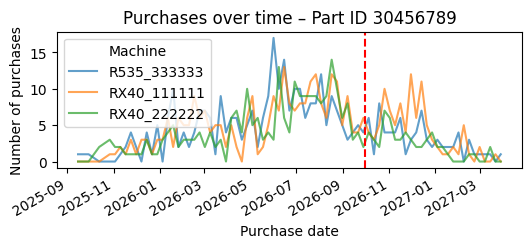

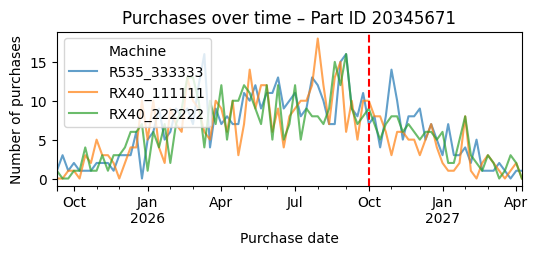

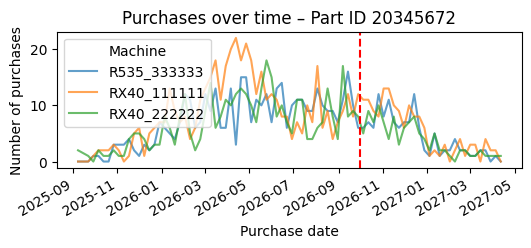

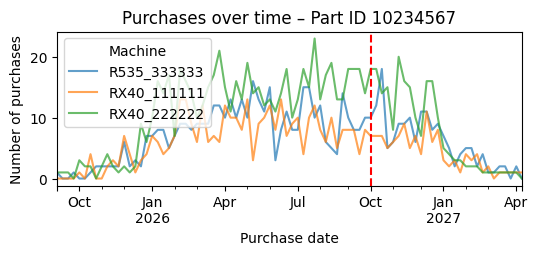

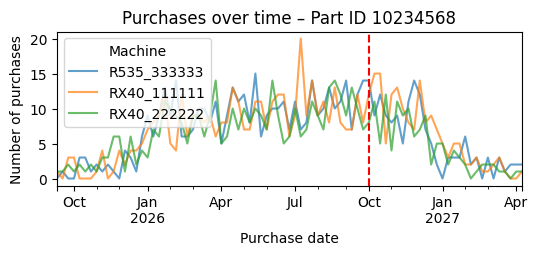

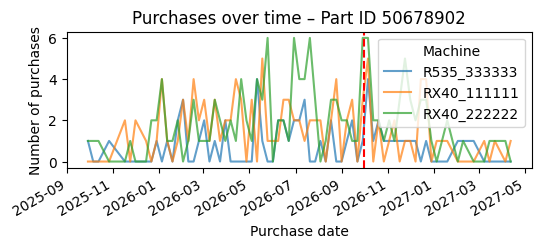

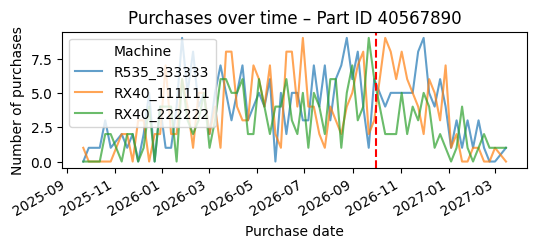

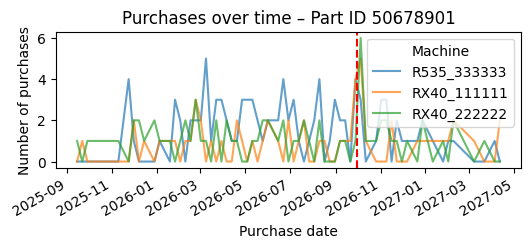

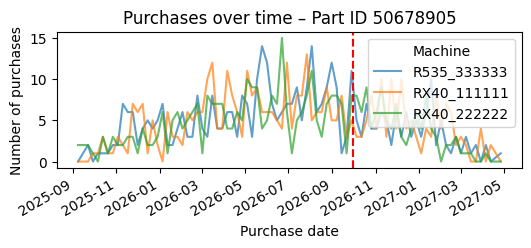

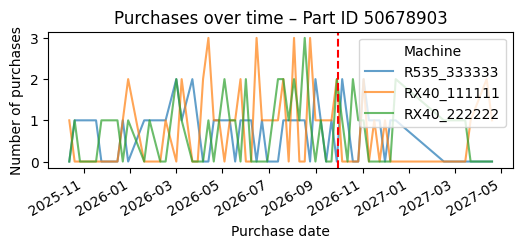

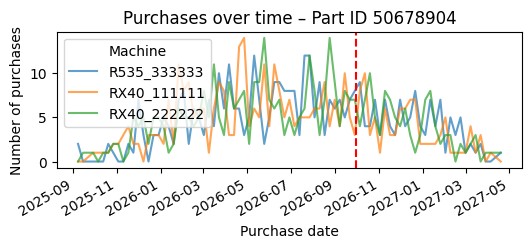

In [23]:
# Part ID & Maschines Timeseries
for part_id in df_part['Part_id'].unique():
    pd.crosstab(
        index=df_part.loc[df_part['Part_id'] == part_id, 'Week_purchase'],
        columns=df_part.loc[df_part['Part_id'] == part_id, 'Machine']
    ).plot(
        title=f'Purchases over time – Part ID {part_id}',
        xlabel='Purchase date',
        ylabel='Number of purchases',
        alpha=.7,
        figsize=(6,2)

    )
    plt.axvline(
        pd.Timestamp('2026-09-30'),
        color='red',
        linestyle='--',
    )
    plt.show()

In [24]:
df_part

,Machine,Date_purchase,Date_delivery,Part,Part_id,Week_purchase,Week_delivery,Future,Shipping_days
1,RX40_111111,2026-08-22,2026-08-26,heater,30456789,2026-08-17,2026-08-24,0,4
2,R535_333333,2026-09-13,2026-09-16,vacuum_valve_1,20345671,2026-09-07,2026-09-14,0,3
3,RX40_222222,2026-08-31,2026-09-03,vacuum_valve_2,20345672,2026-08-31,2026-08-31,0,3
4,RX40_111111,2026-06-16,2026-06-20,knife_1,10234567,2026-06-15,2026-06-15,0,4
5,R535_333333,2026-01-05,2026-01-08,vacuum_valv_2,20345672,2026-01-05,2026-01-05,0,3
...,...,...,...,...,...,...,...,...,...
12290,R535_333333,2026-10-02,2026-10-04,machine_frame,50678901,2026-09-28,2026-09-28,1,2
12291,R535_333333,2026-10-02,2026-10-03,machine_frame,50678901,2026-09-28,2026-09-28,1,1
12293,R535_333333,2026-10-08,2026-10-11,die_set,50678902,2026-10-05,2026-10-05,1,3
12297,R535_333333,2026-10-08,2026-10-09,die_set,50678902,2026-10-05,2026-10-05,1,1
